# Hand Gesture Recognition — Assignment 2 experiments

**Computer Vision — Assignment 2 (continuation of A1)**

This notebook runs top to bottom. The heavy work lives in `scripts/` and `src/`;
every number shown here is read from `results/a2/*.csv`, which those scripts write.

* `A2_RETRAIN=1` re-runs each stage's script before reading its results
  (otherwise the saved results are used, so the notebook runs in about a minute).
* `FAST_MODE=1` shortens every training stage (smoke test). FAST runs read and
  write `*_fast.csv`, so they can never be mistaken for real results.

In [1]:
%matplotlib inline

import os
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src.config import FAST, FIG_DIR, RESULTS_DIR, out_name

RETRAIN = os.environ.get("A2_RETRAIN") == "1"


def run_stage(script, *args):
    """Run one stage script and show the tail of its log."""
    proc = subprocess.run([sys.executable, script, *args], capture_output=True, text=True,
                          encoding="utf-8", errors="replace")
    print("\n".join(proc.stdout.splitlines()[-25:]))
    if proc.returncode:
        print(proc.stderr[-3000:])
        raise RuntimeError(f"{script} failed")


print(f"python {sys.version.split()[0]} | retrain {RETRAIN} | fast {FAST}")

python 3.14.0 | retrain False | fast False


## Stage 0 — reproduce the A1 baseline before changing anything

The A1 code was refactored into `src/` (`data.py`, `train.py`, `models.py`,
`metrics.py`). Before any A2 change, the refactored code must reproduce the A1
ResNet-18 result: **acc 0.945, macro-F1 0.947, 11 errors, all thumb→peace**.

Seed 42 is the A1 seed and runs on the A1 environment (torch 2.14.0+cpu), so it
should match exactly. Seeds 43 and 44 re-run the *unchanged* A1 recipe to show how
much of 0.945 is seed luck. These three runs are also the **B0** baseline for Stage 3.

In [2]:
if RETRAIN:
    run_stage("scripts/stage0_reproduce.py", "--device", "cpu")

res0 = pd.read_csv(RESULTS_DIR / out_name("stage0_reproduce"))
cols = ["seed", "device", "acc", "macro_f1", "n_errors", "error_pattern",
        "acc_fist2_dark", "acc_peace2", "acc_thumb2", "best_val_acc", "train_seconds"]
display(res0[cols].round(4))
print(f"A1 reference          : acc 0.9450   macro-F1 0.9474   11 errors (thumb->peace:11)")
print(f"seed 42 reproduction  : acc {res0.acc[0]:.4f}   macro-F1 {res0.macro_f1[0]:.4f}   "
      f"{res0.n_errors[0]} errors ({res0.error_pattern[0]})")
print(f"B0 over {len(res0)} seeds    : acc {res0.acc.mean():.4f} ± {res0.acc.std(ddof=1):.4f}   "
      f"macro-F1 {res0.macro_f1.mean():.4f} ± {res0.macro_f1.std(ddof=1):.4f}")

,seed,device,acc,macro_f1,n_errors,error_pattern,acc_fist2_dark,acc_peace2,acc_thumb2,best_val_acc,train_seconds
0,42,cpu,0.945,0.9474,11,thumb->peace:11,1.0,1.0,0.8625,0.9694,524.5
1,43,cpu,0.890,0.8909,22,"thumb->fist:10, thumb->peace:12",1.0,1.0,0.7250,1.0000,518.2
2,44,cpu,0.905,0.9088,19,"thumb->fist:1, thumb->peace:18",1.0,1.0,0.7625,0.9694,516.8


A1 reference          : acc 0.9450   macro-F1 0.9474   11 errors (thumb->peace:11)
seed 42 reproduction  : acc 0.9450   macro-F1 0.9474   11 errors (thumb->peace:11)
B0 over 3 seeds    : acc 0.9133 ± 0.0284   macro-F1 0.9157 ± 0.0289


### B0 training curves (3 seeds)

The dashed line marks the unfreeze point: 6 head-only epochs, then 12 full fine-tune epochs.
Validation is the A1 one: the last 20% of every training clip. It is drawn from the
same recordings as the training frames, so it overstates test accuracy (A1 §5).

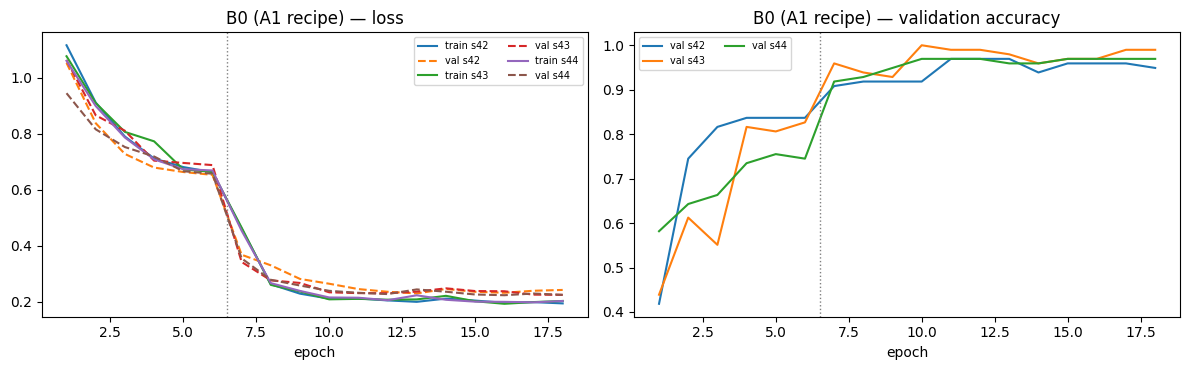

In [3]:
hist0 = pd.read_csv(RESULTS_DIR / out_name("stage0_history"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for seed, h in hist0.groupby("seed"):
    axes[0].plot(h.epoch, h.train_loss, label=f"train s{seed}")
    axes[0].plot(h.epoch, h.val_loss, ls="--", label=f"val s{seed}")
    axes[1].plot(h.epoch, h.val_acc, label=f"val s{seed}")
n_head = int((hist0[hist0.seed == hist0.seed.iloc[0]].stage == "head").sum())
for ax, title in zip(axes, ["loss", "validation accuracy"]):
    ax.axvline(n_head + 0.5, color="grey", ls=":", lw=1)
    ax.set_xlabel("epoch")
    ax.set_title(f"B0 (A1 recipe) — {title}")
    ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / out_name("stage0_curves", "png"), dpi=120, bbox_inches="tight")
plt.show()

### What the A1 centre crop threw away on the misclassified frames

A1 fed the model the central 1072×1072 square of each 1072×1920 portrait frame.
The figure re-reads every seed-42 error from the original `.MOV` and outlines that
square in red: everything outside it was never seen by the model.

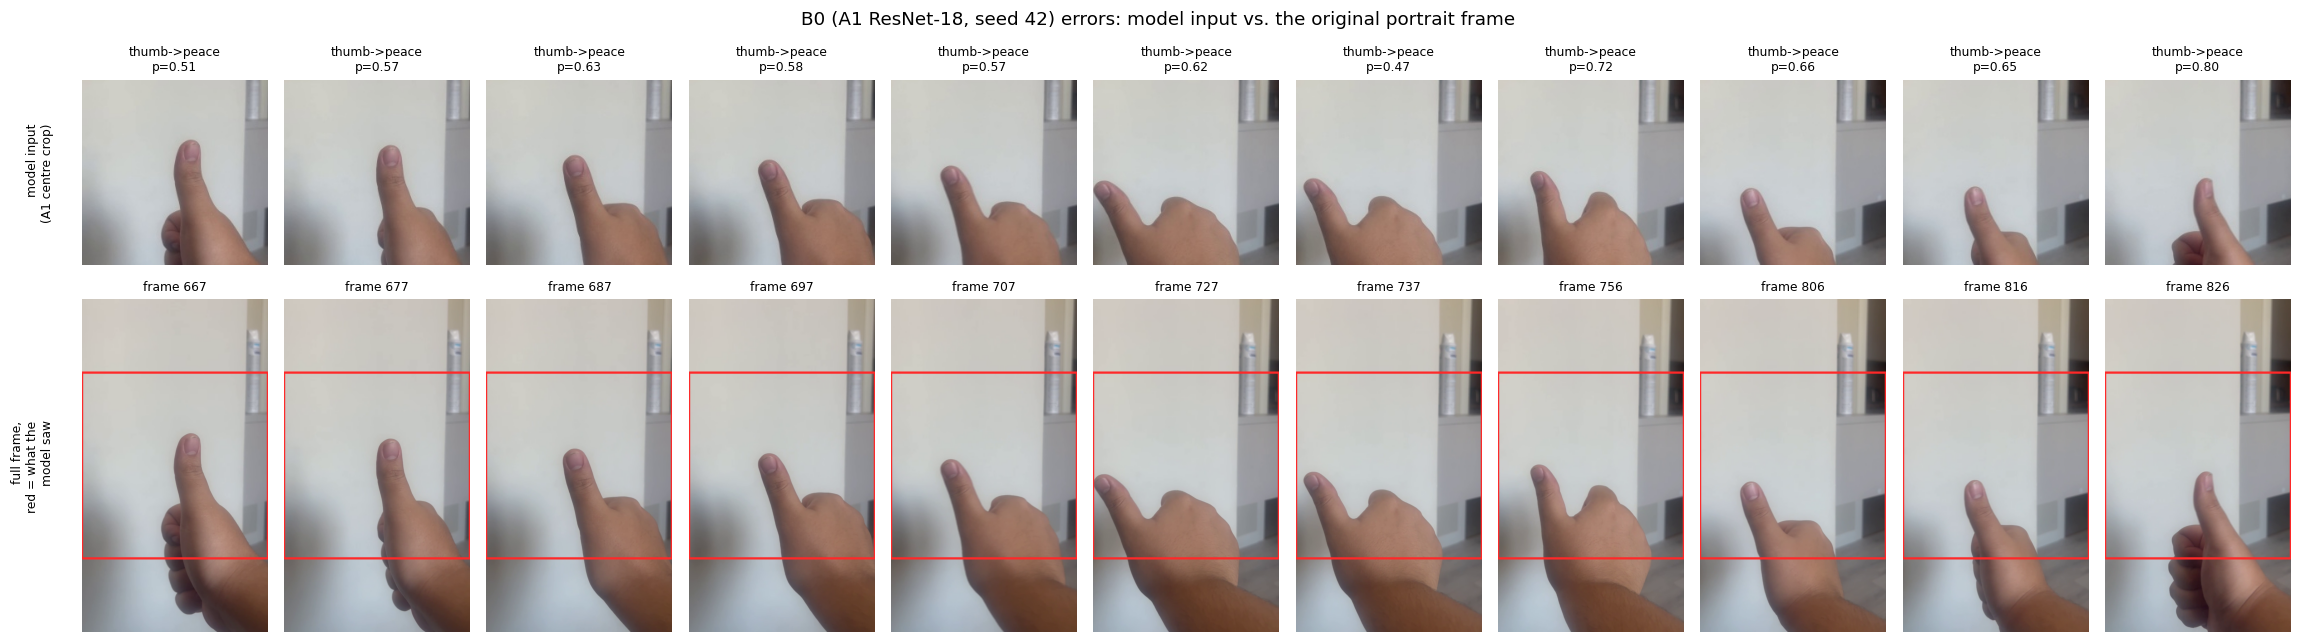

In [4]:
if RETRAIN or not (FIG_DIR / "stage0_errors_fullframe.png").exists():
    run_stage("scripts/inspect_closeups.py")
display(Image(filename=str(FIG_DIR / "stage0_errors_fullframe.png")))